# Nhiệm vụ 3: Học có giám sát – Pipeline Hồi quy (Regression)

Dữ liệu: `cgv_eda_cleaned.csv`.

Các bước:
1. **Đặc trưng mục tiêu:** dự đoán một giá trị số liên tục (doanh thu của mỗi suất chiếu)
2. **Thuật toán:** `LinearRegression()` và `DecisionTreeRegressor()`
3. **Kiểm định & đánh giá:** `train_test_split`, các chỉ số MSE, RMSE, R²
4. **Đầu ra chẩn đoán:** Actual vs Predicted và Residual Plot để kiểm tra lỗi dự đoán có mang tính hệ thống hay không

## 1. Đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
print("Số dòng:", len(df), "| Số cột:", len(df.columns))
df.head(3)

Số dòng: 1172 | Số cột: 18


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,65000,72,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải n...",70000,65,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,75000,53,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0


## 2. Đặc trưng mục tiêu (Target Feature)

Dữ liệu là lịch chiếu, mỗi dòng là một suất chiếu. Biến mục tiêu được chọn là **doanh thu ước tính của suất chiếu**:

`Revenue = TicketPrice × số vé đã bán = TicketPrice × (TotalSeats − AvailableSeats)`

Đây là giá trị số liên tục (đơn vị VND) và đúng với ví dụ "doanh thu" trong yêu cầu. Bài toán đặt ra: *dự đoán doanh thu của một suất chiếu dựa trên các thuộc tính lịch chiếu* (phim, rạp, định dạng, giờ chiếu...).

count       1172.0
mean     2723993.0
std      1295969.0
min            0.0
25%      1760000.0
50%      2660000.0
75%      3503750.0
max      9085000.0
Name: Revenue, dtype: float64


/tmp/ipykernel_195/2815457909.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df["Revenue"] / 1e6, vert=False)


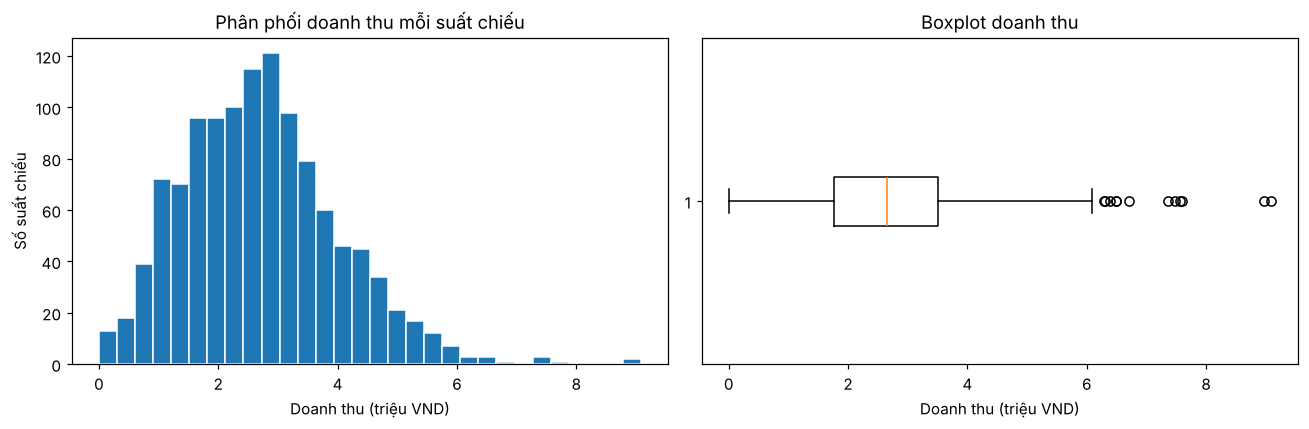

In [2]:
df["SoldSeats"] = df["TotalSeats"] - df["AvailableSeats"]
df["Revenue"] = df["TicketPrice"] * df["SoldSeats"]

print(df["Revenue"].describe().round(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Revenue"] / 1e6, bins=30, color="#1f77b4", edgecolor="white")
axes[0].set_title("Phân phối doanh thu mỗi suất chiếu")
axes[0].set_xlabel("Doanh thu (triệu VND)")
axes[0].set_ylabel("Số suất chiếu")
axes[1].boxplot(df["Revenue"] / 1e6, vert=False)
axes[1].set_title("Boxplot doanh thu")
axes[1].set_xlabel("Doanh thu (triệu VND)")
plt.tight_layout()
plt.show()

**Nhận xét:** Doanh thu trung bình mỗi suất khoảng 2,72 triệu đồng, trung vị 2,66 triệu đồng, độ lệch chuẩn 1,30 triệu đồng, trải từ 0 đến 9,09 triệu đồng và lệch phải nhẹ (skewness 0,65). Có 1 suất doanh thu bằng 0 (chưa bán được vé nào). Phân phối khá liên tục nên phù hợp với bài toán hồi quy.

## 3. Chuẩn bị đặc trưng đầu vào (X)

Các đặc trưng được tạo từ thông tin có sẵn **trước khi suất chiếu diễn ra**:
- Số: `DurationMinutes`, `ShowHour`, `DaysSinceRelease`, `IsWeekend`, `IsPremiumRoom`, `TotalSeats`
- Biến phân loại → số: one-hot `Cinema`, `Rating`, loại định dạng chiếu (`FormatTech`); multi-hot `Genre`

**Tránh rò rỉ dữ liệu (data leakage):** loại `TicketPrice`, `AvailableSeats`, `SoldSeats` khỏi X vì chính chúng cấu thành biến mục tiêu. Mục 3.1 chứng minh vì sao.

In [3]:
feat = pd.DataFrame(index=df.index)

feat["DurationMinutes"] = pd.to_numeric(df["DurationMinutes"], errors="coerce")
t = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce")
feat["ShowHour"] = t.dt.hour + t.dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)
feat["TotalSeats"] = pd.to_numeric(df["TotalSeats"], errors="coerce")

cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X = pd.concat([feat, cat_dummies, genre_dummies], axis=1)
y = df["Revenue"]

print("Kích thước X:", X.shape)
print("Giá trị thiếu trong X:", int(X.isna().sum().sum()))
X.head(3)

Kích thước X: (1172, 30)
Giá trị thiếu trong X: 0


,DurationMinutes,ShowHour,DaysSinceRelease,IsWeekend,IsPremiumRoom,TotalSeats,Cinema_CGV Crescent Mall,Cinema_CGV Hùng Vương Plaza,Cinema_CGV Thảo Điền Pearl,Cinema_CGV Vincom Thủ Đức,...,Genre_Gia đình,Genre_Hoạt Hình,Genre_Hài,Genre_Hành Động,Genre_Hồi hộp,Genre_Khoa Học Viễn Tưởng,Genre_Kinh Dị,Genre_Phiêu Lưu,Genre_Thần thoại,Genre_Tâm Lý
0,183.0,10.5,6,0,1,100,1,0,0,0,...,0,0,0,1,0,1,0,1,0,0
1,183.0,16.0,6,0,1,100,1,0,0,0,...,0,0,0,1,0,1,0,1,0,0
2,183.0,21.5,6,0,1,100,1,0,0,0,...,0,0,0,1,0,1,0,1,0,0


### 3.1. Kiểm tra rò rỉ dữ liệu (minh họa)

Nếu đưa `AvailableSeats` và `TicketPrice` vào X, mô hình đạt R² gần 1 một cách giả tạo vì biến mục tiêu được tính trực tiếp từ hai cột này.

In [4]:
X_leak = X.assign(TicketPrice=df["TicketPrice"], AvailableSeats=df["AvailableSeats"])
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X_leak, y, test_size=0.2, random_state=RANDOM_STATE)
leak_r2 = r2_score(yl_te, LinearRegression().fit(Xl_tr, yl_tr).predict(Xl_te))
print(f"R² nếu để rò rỉ (chỉ để minh họa, KHÔNG dùng): {leak_r2:.3f}")

R² nếu để rò rỉ (chỉ để minh họa, KHÔNG dùng): 0.981


**Nhận xét:** Nếu đưa `TicketPrice` và `AvailableSeats` vào X, R² vọt lên 0,981 (so với 0,671 của mô hình tốt nhất), vì doanh thu được tính trực tiếp từ hai cột này. Đây là rò rỉ dữ liệu nên hai cột này bị loại khỏi đặc trưng đầu vào.

## 4. Chia tập Train / Test

Dùng `train_test_split` với tỉ lệ 80% huấn luyện / 20% kiểm tra, cố định `random_state` để kết quả lặp lại được.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (937, 30) | Test: (235, 30)


## 5. Huấn luyện và so sánh mô hình

- **Mô hình cơ sở (Dummy):** luôn dự đoán trung bình, dùng làm mốc (R² ≈ 0).
- **LinearRegression:** chuẩn hóa đặc trưng bằng `StandardScaler` rồi hồi quy tuyến tính.
- **DecisionTreeRegressor (mặc định):** không giới hạn độ sâu, dễ overfit.
- **DecisionTreeRegressor (đã tinh chỉnh):** tìm `max_depth` và `min_samples_leaf` bằng `GridSearchCV` (5-fold) chỉ trên tập train.

In [6]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)

lin_reg = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)

tree_default = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"max_depth": [2, 3, 4, 5, 6, 8, 10],
                "min_samples_leaf": [5, 10, 20, 40]},
    cv=5, scoring="r2",
).fit(X_train, y_train)
tree_tuned = grid.best_estimator_

print("Tham số tốt nhất của cây quyết định:", grid.best_params_)

Tham số tốt nhất của cây quyết định: {'max_depth': 6, 'min_samples_leaf': 10}


## 6. Đánh giá bằng MSE, RMSE và R²

In [7]:
models = {
    "Baseline (trung bình)": dummy,
    "LinearRegression": lin_reg,
    "DecisionTree (mặc định)": tree_default,
    "DecisionTree (tinh chỉnh)": tree_tuned,
}

def evaluate(model, Xa, ya):
    pred = model.predict(Xa)
    mse = mean_squared_error(ya, pred)
    return mse, np.sqrt(mse), r2_score(ya, pred)

rows = []
for name, mdl in models.items():
    tr_mse, tr_rmse, tr_r2 = evaluate(mdl, X_train, y_train)
    te_mse, te_rmse, te_r2 = evaluate(mdl, X_test, y_test)
    cv_r2 = cross_val_score(mdl, X, y, cv=5, scoring="r2").mean()
    rows.append({
        "Mô hình": name,
        "MSE (test)": te_mse,
        "RMSE (test)": te_rmse,
        "R² (test)": te_r2,
        "R² (train)": tr_r2,
        "R² (CV 5-fold)": cv_r2,
    })

results = pd.DataFrame(rows).set_index("Mô hình")
pd.options.display.float_format = "{:,.3f}".format
display(results)

,MSE (test),RMSE (test),R² (test),R² (train),R² (CV 5-fold)
Mô hình,,,,,
Baseline (trung bình),"1,509,335,667,004.964","1,228,550.230",-0.017,0.000,-0.013
LinearRegression,"721,026,041,562.559","849,132.523",0.514,0.592,0.542
DecisionTree (mặc định),"813,167,340,425.532","901,757.917",0.452,1.000,0.537
DecisionTree (tinh chỉnh),"488,419,238,989.974","698,869.973",0.671,0.798,0.712


In [8]:
best_name = results["R² (test)"].drop("Baseline (trung bình)").idxmax()
print("Mô hình có R² test cao nhất:", best_name)
print(f"RMSE (test) = {results.loc[best_name, 'RMSE (test)']:,.0f} VND "
      f"(so với độ lệch chuẩn của doanh thu = {y.std():,.0f} VND)")

Mô hình có R² test cao nhất: DecisionTree (tinh chỉnh)
RMSE (test) = 698,870 VND (so với độ lệch chuẩn của doanh thu = 1,295,969 VND)


**Nhận xét:** Kết quả trên 5-fold CV (0,712) và tập test (0,671) gần nhau, cho thấy R² không phải do may mắn trong một lần chia dữ liệu. Sai số RMSE 698.870 đồng còn lớn so với doanh thu trung bình 2,72 triệu đồng (khoảng 26%), tức mô hình dự đoán đúng xu hướng nhưng chưa chính xác từng suất.

**Cách đọc kết quả:**
- **R² (train) so với R² (test):** nếu train cao nhưng test thấp hoặc âm, mô hình bị overfit (thường gặp ở cây không giới hạn độ sâu).
- **R² (CV 5-fold):** kiểm tra độ ổn định, tránh phụ thuộc vào một lần chia train/test duy nhất.
- **RMSE:** sai số trung bình tính bằng VND, so sánh với mốc dự đoán trung bình để biết mô hình cải thiện được bao nhiêu.

**Kết quả trên dữ liệu v3:**
- Mốc (đoán trung bình) có R² gần 0 (−0,017 trên test), RMSE 1.228.550 đồng.
- `DecisionTree` mặc định overfit: R² train = 1,000 nhưng R² test chỉ 0,452 và CV 0,537.
- `LinearRegression`: R² test 0,514, CV 0,542, ổn định (train 0,592).
- `DecisionTree` tinh chỉnh (`max_depth = 6`, `min_samples_leaf = 10`) tốt nhất: **R² test 0,671, CV 0,712, RMSE 698.870 đồng**, giảm khoảng 43% sai số so với mốc. R² train (0,798) cao hơn test nhưng không quá xa, và CV (0,712) gần với test nên mô hình khá ổn định.
- R² kiểm tra chéo cao (0,54–0,71) và gần với R² test, khác hẳn dữ liệu cũ (R² CV chỉ khoảng 0,09): lần này các thuộc tính lịch chiếu thật sự chứa tín hiệu.

## 7. Đầu ra chẩn đoán

### 7.1. Biểu đồ Thực tế so với Dự đoán (Actual vs Predicted)

Điểm nằm sát đường chéo đỏ nghĩa là dự đoán chính xác.

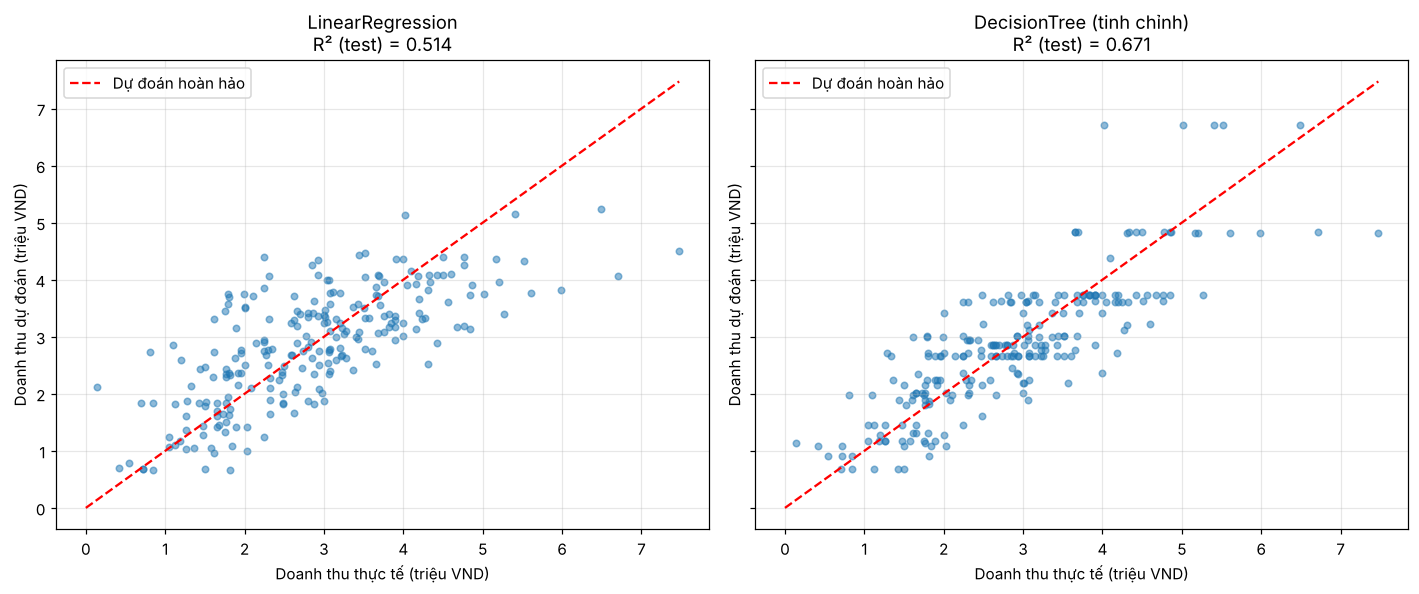

In [9]:
compare_models = {
    "LinearRegression": lin_reg,
    "DecisionTree (tinh chỉnh)": tree_tuned,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
lim = max(y_test.max(), 1) / 1e6

for ax, (name, mdl) in zip(axes, compare_models.items()):
    pred = mdl.predict(X_test)
    ax.scatter(y_test / 1e6, pred / 1e6, s=18, alpha=0.5, color="#1f77b4")
    ax.plot([0, lim], [0, lim], color="red", linestyle="--", label="Dự đoán hoàn hảo")
    ax.set_title(f"{name}\nR² (test) = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Doanh thu thực tế (triệu VND)")
    ax.set_ylabel("Doanh thu dự đoán (triệu VND)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

**Nhận xét Actual vs Predicted:**
- `LinearRegression` (R² 0,514): các điểm tụ quanh đường chéo nhưng tản rộng; ở vùng doanh thu cao (trên 5 triệu) mô hình dự đoán thấp hơn thực tế rõ rệt.
- `DecisionTree` tinh chỉnh (R² 0,671): dự đoán chỉ nhận một số giá trị rời rạc (các hàng ngang) vì cây chỉ có vài lá. Điểm sát đường chéo hơn ở vùng doanh thu thấp và trung bình, nhưng ở vùng cao có vài điểm bị lệch lớn: dự đoán 6,7 triệu trong khi thực tế chỉ khoảng 4–5,5 triệu, và dự đoán khoảng 4,8 triệu trong khi thực tế có suất tới 6–7,5 triệu.

### 7.2. Biểu đồ phần dư (Residual Plot)

Phần dư = Thực tế − Dự đoán. Nếu sai số là ngẫu nhiên, các điểm phân tán đều quanh đường 0. Nếu có dạng cong, hình phễu hoặc lệch một phía thì lỗi mang tính hệ thống.

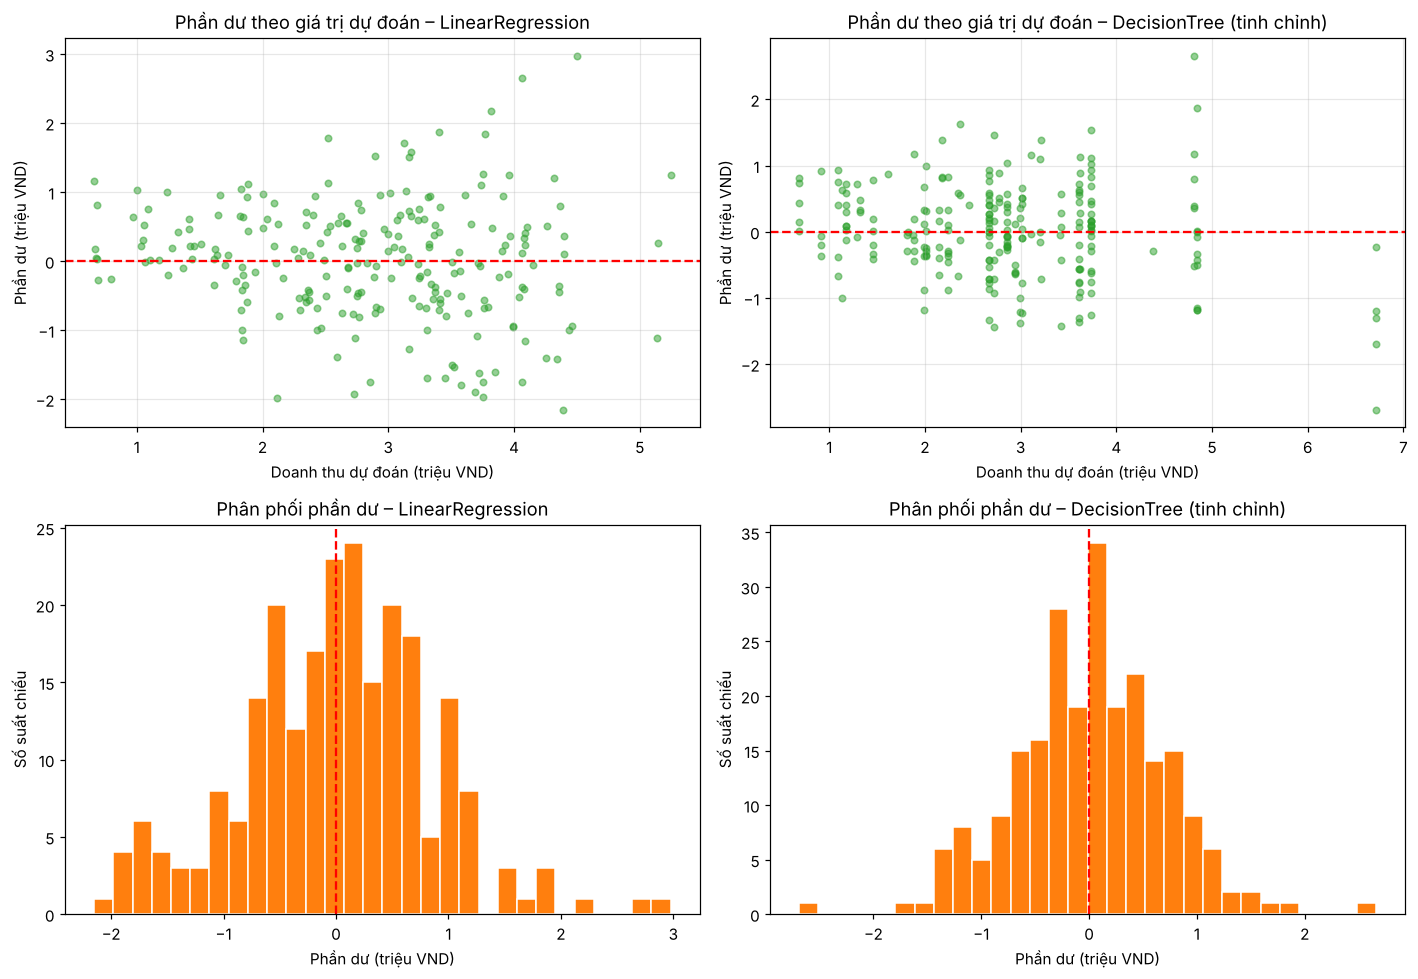

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, (name, mdl) in enumerate(compare_models.items()):
    pred = mdl.predict(X_test)
    resid = y_test - pred

    axes[0, col].scatter(pred / 1e6, resid / 1e6, s=18, alpha=0.5, color="#2ca02c")
    axes[0, col].axhline(0, color="red", linestyle="--")
    axes[0, col].set_title(f"Phần dư theo giá trị dự đoán – {name}")
    axes[0, col].set_xlabel("Doanh thu dự đoán (triệu VND)")
    axes[0, col].set_ylabel("Phần dư (triệu VND)")
    axes[0, col].grid(alpha=0.3)

    axes[1, col].hist(resid / 1e6, bins=30, color="#ff7f0e", edgecolor="white")
    axes[1, col].axvline(0, color="red", linestyle="--")
    axes[1, col].set_title(f"Phân phối phần dư – {name}")
    axes[1, col].set_xlabel("Phần dư (triệu VND)")
    axes[1, col].set_ylabel("Số suất chiếu")

plt.tight_layout()
plt.show()

**Nhận xét phần dư:**
- Phân phối phần dư của cả hai mô hình khá đối xứng quanh 0 và gần dạng chuông, nên không bị lệch hẳn về một phía.
- `LinearRegression`: phần dư tản rộng dần khi doanh thu dự đoán tăng (hình phễu nhẹ), tức sai số lớn hơn ở các suất doanh thu cao.
- `DecisionTree`: phần dư xếp thành các cột dọc theo từng giá trị dự đoán; vài điểm ở các cột 4,8 và 6,7 triệu có phần dư lên tới ±2–3 triệu.
- Hai mô hình đều chưa có dạng cong rõ rệt, nhưng vẫn còn sai lệch ở hai đầu giá trị (mục 7.3).

### 7.3. Lỗi có mang tính hệ thống không?

Chia tập test theo nhóm doanh thu thực tế và xem phần dư trung bình của từng nhóm. Nếu mô hình thường dự đoán thấp cho nhóm doanh thu cao (và cao cho nhóm thấp), đó là sai lệch có hệ thống.

In [11]:
pred_best = tree_tuned.predict(X_test)
diag = pd.DataFrame({"Actual": y_test.values, "Pred": pred_best})
diag["Residual"] = diag["Actual"] - diag["Pred"]
diag["Nhom_doanh_thu"] = pd.qcut(diag["Actual"], 4, duplicates="drop",
                                 labels=None)

summary = diag.groupby("Nhom_doanh_thu", observed=True).agg(
    So_suat=("Residual", "size"),
    Phan_du_TB=("Residual", "mean"),
    Phan_du_tuyet_doi_TB=("Residual", lambda s: s.abs().mean()),
).round(0)
display(summary)

print(f"Phần dư trung bình toàn bộ tập test: {diag['Residual'].mean():,.0f} VND")

,So_suat,Phan_du_TB,Phan_du_tuyet_doi_TB
Nhom_doanh_thu,,,
"(139999.999, 1887500.0]",59,"-223,064.000","481,916.000"
"(1887500.0, 2835000.0]",59,"-251,203.000","481,618.000"
"(2835000.0, 3655000.0]",60,"185,783.000","477,582.000"
"(3655000.0, 7475000.0]",57,"344,384.000","711,648.000"


Phần dư trung bình toàn bộ tập test: 11,894 VND


**Nhận xét 7.3:** Sai số vẫn mang tính hệ thống nhưng ở mức vừa phải. Với hai nhóm doanh thu thấp nhất, mô hình dự đoán cao hơn thực tế (phần dư trung bình −223.000 và −251.000 đồng), còn với hai nhóm doanh thu cao, mô hình dự đoán thấp hơn (+186.000 và +344.000 đồng). Mô hình có xu hướng kéo dự đoán về phía trung bình. Nhóm doanh thu cao nhất sai nhiều nhất (sai số tuyệt đối trung bình 712.000 đồng so với khoảng 480.000 đồng ở ba nhóm còn lại). Phần dư trung bình toàn bộ tập test chỉ 11.894 đồng, tức mô hình không lệch tổng thể.

## 8. Đặc trưng nào ảnh hưởng nhiều nhất?

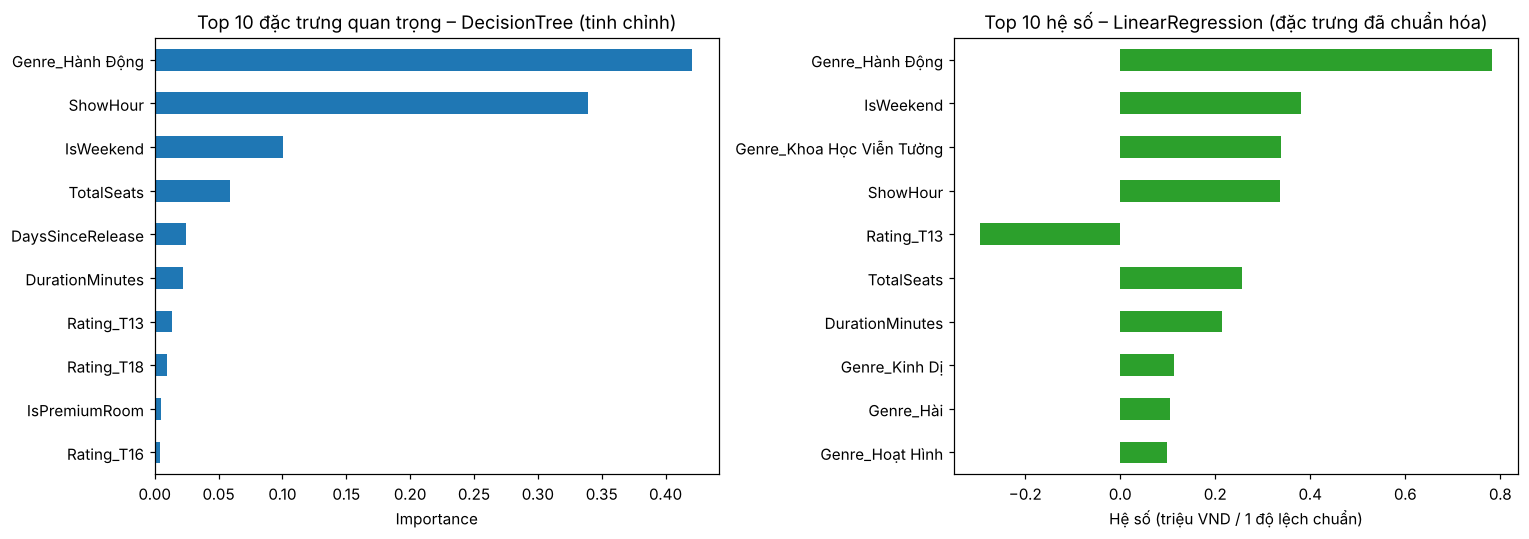

In [12]:
importances = pd.Series(tree_tuned.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importances.head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top[::-1].plot(kind="barh", ax=axes[0], color="#1f77b4")
axes[0].set_title("Top 10 đặc trưng quan trọng – DecisionTree (tinh chỉnh)")
axes[0].set_xlabel("Importance")

coef = pd.Series(lin_reg.named_steps["linearregression"].coef_, index=X.columns)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
(top_coef[::-1] / 1e6).plot(kind="barh", ax=axes[1], color="#2ca02c")
axes[1].set_title("Top 10 hệ số – LinearRegression (đặc trưng đã chuẩn hóa)")
axes[1].set_xlabel("Hệ số (triệu VND / 1 độ lệch chuẩn)")

plt.tight_layout()
plt.show()

**Nhận xét đặc trưng:**
- Cây quyết định dựa chủ yếu vào `Genre_Hành Động` (khoảng 0,42), `ShowHour` (khoảng 0,34), `IsWeekend` (khoảng 0,10) và `TotalSeats` (khoảng 0,06); các đặc trưng còn lại đóng góp rất ít.
- `LinearRegression` cũng xếp `Genre_Hành Động`, `IsWeekend`, `Genre_Khoa Học Viễn Tưởng` và `ShowHour` ở đầu, `Rating_T13` có hệ số âm.
- `Genre_Hành Động` xuất hiện trong 66,7% số suất, và suất nhóm này có doanh thu trung bình 3,25 triệu đồng so với 1,67 triệu của nhóm còn lại. Do đó nó chủ yếu là **đại diện cho các phim hot** (Trại buồn người, Avengers, Vùng đất quỷ dữ đều có nhãn Hành Động) chứ không phải do thể loại tự nó thu hút khách.
- `ShowHour` và `IsWeekend` cho thấy suất giờ vàng (doanh thu trung bình 3,89 triệu so với 2,30 triệu của các giờ khác) và cuối tuần (3,13 triệu so với 2,42 triệu) có doanh thu cao hơn.
- Các tín hiệu này là do **quy luật đã đặt khi mô phỏng dữ liệu** (phim hot, giờ vàng, cuối tuần), nên mô hình học lại được là điều dễ hiểu.

## 9. Kết luận

- **Biến mục tiêu:** doanh thu mỗi suất chiếu = giá vé × số vé đã bán.
- **Quy trình:** chia train/test 80/20, huấn luyện `LinearRegression` và `DecisionTreeRegressor` (mặc định và tinh chỉnh bằng `GridSearchCV`), đánh giá bằng MSE, RMSE, R² kèm kiểm tra chéo 5-fold; loại `TicketPrice`, `AvailableSeats` khỏi X để tránh rò rỉ (R² rò rỉ là 0,981).
- **Đánh giá:** cây quyết định tinh chỉnh (`max_depth = 6`, `min_samples_leaf = 10`) là mô hình tốt nhất: **R² test 0,671, R² CV 5-fold 0,712, RMSE 698.870 đồng**, giảm khoảng 43% sai số so với đoán trung bình (RMSE 1.228.550 đồng). `LinearRegression` đạt R² test 0,514 (CV 0,542). Cây mặc định overfit (R² train 1,0, test 0,452).
- **Chẩn đoán:** phần dư đối xứng quanh 0 (trung bình 11.894 đồng) nhưng vẫn có xu hướng kéo về trung bình: dự đoán cao hơn cho suất doanh thu thấp (−223.000 đến −251.000 đồng) và thấp hơn cho suất doanh thu cao (+186.000 đến +344.000 đồng). Sai số lớn nhất ở nhóm doanh thu cao nhất.
- **Đặc trưng quan trọng:** `Genre_Hành Động` (đại diện cho phim hot), `ShowHour`, `IsWeekend` và `TotalSeats`.
- **Hạn chế:** ba cột `TicketPrice`, `TotalSeats`, `AvailableSeats` là dữ liệu **mô phỏng theo quy luật giả định** (phim hot, giờ vàng, cuối tuần, loại phòng), nên R² khá cao phản ánh việc mô hình học lại quy luật đã đặt chứ không phải hành vi khách hàng thật của CGV. Chỉ có 10 ngày lịch chiếu của 5 rạp nên kết quả không thể khái quát cho toàn hệ thống. Cần dữ liệu bán vé thực tế để kiểm chứng.